<a href="https://colab.research.google.com/github/SanviBallal/Factory-Shipping-Optimization/blob/main/05_factory_customer_distance_calculation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np

# Load original dataset
df = pd.read_csv("/content/Nassau Candy Distributor.csv")

# Load combined factory mapping
factory_mapping_df = pd.read_csv(
    "/content/combined_product_factory_mapping.csv"
)

print("Both datasets loaded successfully!")

print("Original dataset shape:", df.shape)
print("Factory mapping shape:", factory_mapping_df.shape)

Both datasets loaded successfully!
Original dataset shape: (10194, 18)
Factory mapping shape: (15, 4)


In [2]:
print("CUSTOMER LOCATION DETAILS")
print("------------------------------")

display(
    df[["Country/Region", "City", "State/Province", "Postal Code"]].head(10)
)

print("Unique countries:", df["Country/Region"].nunique())
print("Unique cities:", df["City"].nunique())
print("Unique postal codes:", df["Postal Code"].nunique())

CUSTOMER LOCATION DETAILS
------------------------------


,Country/Region,City,State/Province,Postal Code
0,United States,Houston,Texas,77095
1,United States,Naperville,Illinois,60540
2,United States,Naperville,Illinois,60540
3,United States,Naperville,Illinois,60540
4,United States,Philadelphia,Pennsylvania,19143
5,United States,Henderson,Kentucky,42420
6,United States,Henderson,Kentucky,42420
7,United States,Athens,Georgia,30605
8,United States,Henderson,Kentucky,42420
9,United States,Henderson,Kentucky,42420


Unique countries: 2
Unique cities: 542
Unique postal codes: 654


In [3]:
print("COUNTRY-WISE CUSTOMER DISTRIBUTION")
print("----------------------------------")

display(
    df["Country/Region"].value_counts().reset_index()
)

COUNTRY-WISE CUSTOMER DISTRIBUTION
----------------------------------


,Country/Region,count
0,United States,9994
1,Canada,200


In [4]:
customer_locations = df[
    ["Country/Region", "State/Province", "City", "Postal Code"]
].drop_duplicates()

customer_locations = customer_locations.reset_index(drop=True)

print("UNIQUE CUSTOMER LOCATIONS")
print("------------------------------")

print("Total unique locations:", len(customer_locations))

display(customer_locations.head(10))

UNIQUE CUSTOMER LOCATIONS
------------------------------
Total unique locations: 655


,Country/Region,State/Province,City,Postal Code
0,United States,Texas,Houston,77095
1,United States,Illinois,Naperville,60540
2,United States,Pennsylvania,Philadelphia,19143
3,United States,Kentucky,Henderson,42420
4,United States,Georgia,Athens,30605
5,United States,California,Los Angeles,90049
6,United States,Texas,Huntsville,77340
7,United States,Texas,Laredo,78041
8,United States,Virginia,Springfield,22153
9,United States,Delaware,Dover,19901


In [5]:
postal_check = (
    customer_locations.groupby("Postal Code")
    .size()
    .reset_index(name="Location Count")
)

multiple_locations = postal_check[
    postal_check["Location Count"] > 1
]

print("POSTAL CODE VALIDATION")
print("------------------------------")

print("Unique postal codes:", postal_check.shape[0])
print("Postal codes linked to multiple locations:", len(multiple_locations))

display(multiple_locations)

POSTAL CODE VALIDATION
------------------------------
Unique postal codes: 654
Postal codes linked to multiple locations: 1


,Postal Code,Location Count
538,92024,2


In [7]:
display(
    customer_locations[
        customer_locations["Postal Code"] == "92024"
    ]
)

,Country/Region,State/Province,City,Postal Code
36,United States,California,San Diego,92024
509,United States,California,Encinitas,92024


In [8]:
print("CUSTOMER LOCATION DATA QUALITY")
print("--------------------------------")

print(customer_locations.isnull().sum())

print(
    "Blank city names:",
    customer_locations["City"].astype(str).str.strip().eq("").sum()
)

print(
    "Blank state names:",
    customer_locations["State/Province"].astype(str).str.strip().eq("").sum()
)

CUSTOMER LOCATION DATA QUALITY
--------------------------------
Country/Region    0
State/Province    0
City              0
Postal Code       0
dtype: int64
Blank city names: 0
Blank state names: 0


In [9]:
!pip -q install geopy

In [10]:
from geopy.geocoders import Nominatim

# Connect to OpenStreetMap
geolocator = Nominatim(
    user_agent="nassau_factory_shipping_optimization_project"
)

# Select the first customer location
sample = customer_locations.iloc[0]

# Prepare the location query
query = (
    f"{sample['City']}, "
    f"{sample['State/Province']}, "
    f"{sample['Postal Code']}, "
    f"{sample['Country/Region']}"
)

# Get geographical coordinates
location = geolocator.geocode(
    query,
    exactly_one=True,
    timeout=15
)

if location:
    print("Location found!")
    print("Address:", location.address)
    print("Latitude:", location.latitude)
    print("Longitude:", location.longitude)
else:
    print("Location not found.")

Location found!
Address: Houston, Harris County, Texas, United States
Latitude: 29.7589382
Longitude: -95.3676974


In [11]:
import requests

# Download US postal-code data
us_url = "https://download.geonames.org/export/zip/US.zip"

# Download full Canadian postal-code data
ca_url = "https://download.geonames.org/export/zip/CA_full.csv.zip"

for url, filename in [
    (us_url, "US.zip"),
    (ca_url, "CA_full.csv.zip")
]:
    response = requests.get(url, timeout=60)
    response.raise_for_status()

    with open(filename, "wb") as file:
        file.write(response.content)

    print(filename, "downloaded successfully!")

US.zip downloaded successfully!
CA_full.csv.zip downloaded successfully!


In [12]:
import zipfile

for filename in ["US.zip", "CA_full.csv.zip"]:
    with zipfile.ZipFile(filename, "r") as z:
        print("\n", filename)
        print(z.namelist())


 US.zip
['readme.txt', 'US.txt']

 CA_full.csv.zip
['CA_full.txt']


In [13]:
import zipfile
import pandas as pd

# Extract US data
with zipfile.ZipFile("US.zip", "r") as z:
    z.extract("US.txt", ".")

# Extract Canada data
with zipfile.ZipFile("CA_full.csv.zip", "r") as z:
    z.extract("CA_full.txt", ".")

# Read US postal-code data
us_geo = pd.read_csv(
    "US.txt",
    sep="\t",
    header=None,
    dtype=str
)

# Read Canadian postal-code data
ca_geo = pd.read_csv(
    "CA_full.txt",
    sep="\t",
    header=None,
    dtype=str
)

print("US reference data shape:", us_geo.shape)
print("Canada reference data shape:", ca_geo.shape)

print("\nUS sample:")
display(us_geo.head())

print("\nCanada sample:")
display(ca_geo.head())

US reference data shape: (41490, 12)
Canada reference data shape: (900676, 12)

US sample:


,0,1,2,3,4,5,6,7,8,9,10,11
0,US,99553,Akutan,Alaska,AK,Aleutians East,013,NaN,NaN,54.143,-165.7854,1
1,US,99571,Cold Bay,Alaska,AK,Aleutians East,013,NaN,NaN,55.1858,-162.7211,1
2,US,99583,False Pass,Alaska,AK,Aleutians East,013,NaN,NaN,54.8542,-163.4113,1
3,US,99612,King Cove,Alaska,AK,Aleutians East,013,NaN,NaN,55.0628,-162.3056,1
4,US,99661,Sand Point,Alaska,AK,Aleutians East,013,NaN,NaN,55.3192,-160.4914,1



Canada sample:


,0,1,2,3,4,5,6,7,8,9,10,11
0,CA,T0A 0A0,Abee,Alberta,AB,NaN,NaN,NaN,NaN,54.1958,-113.1506,6
1,CA,T0A 0A1,Saddle Lake,Alberta,AB,NaN,NaN,NaN,NaN,54.0029,-111.7,6
2,CA,T0A 0A2,Cherry Grove,Alberta,AB,NaN,NaN,NaN,NaN,54.3603,-110.0863,6
3,CA,T0A 0A3,Glendon,Alberta,AB,NaN,NaN,NaN,NaN,54.3455,-111.6157,6
4,CA,T0A 0A4,Lindbergh,Alberta,AB,NaN,NaN,NaN,NaN,54.3455,-111.6157,6


In [14]:
# Define column names
columns = [
    "Country",
    "Postal Code",
    "Place Name",
    "State",
    "State Code",
    "County",
    "County Code",
    "Community",
    "Community Code",
    "Latitude",
    "Longitude",
    "Accuracy"
]

# Assign column names
us_geo.columns = columns
ca_geo.columns = columns

# Keep only the required columns
required_columns = [
    "Country",
    "Postal Code",
    "Place Name",
    "State",
    "Latitude",
    "Longitude",
    "Accuracy"
]

us_geo = us_geo[required_columns].copy()
ca_geo = ca_geo[required_columns].copy()

print("US reference data:")
display(us_geo.head())

print("\nCanada reference data:")
display(ca_geo.head())

US reference data:


,Country,Postal Code,Place Name,State,Latitude,Longitude,Accuracy
0,US,99553,Akutan,Alaska,54.143,-165.7854,1
1,US,99571,Cold Bay,Alaska,55.1858,-162.7211,1
2,US,99583,False Pass,Alaska,54.8542,-163.4113,1
3,US,99612,King Cove,Alaska,55.0628,-162.3056,1
4,US,99661,Sand Point,Alaska,55.3192,-160.4914,1



Canada reference data:


,Country,Postal Code,Place Name,State,Latitude,Longitude,Accuracy
0,CA,T0A 0A0,Abee,Alberta,54.1958,-113.1506,6
1,CA,T0A 0A1,Saddle Lake,Alberta,54.0029,-111.7,6
2,CA,T0A 0A2,Cherry Grove,Alberta,54.3603,-110.0863,6
3,CA,T0A 0A3,Glendon,Alberta,54.3455,-111.6157,6
4,CA,T0A 0A4,Lindbergh,Alberta,54.3455,-111.6157,6


In [15]:
# Convert postal codes into consistent text format

us_geo["Postal Code"] = (
    us_geo["Postal Code"].astype(str).str.strip()
)

ca_geo["Postal Code"] = (
    ca_geo["Postal Code"].astype(str)
    .str.upper()
    .str.replace(" ", "", regex=False)
)

customer_locations["Postal Code"] = (
    customer_locations["Postal Code"].astype(str).str.strip()
)

# Standardize Canadian postal codes in customer data
customer_locations.loc[
    customer_locations["Country/Region"] == "Canada",
    "Postal Code"
] = (
    customer_locations.loc[
        customer_locations["Country/Region"] == "Canada",
        "Postal Code"
    ].str.upper().str.replace(" ", "", regex=False)
)

print("Postal code standardization completed!")

print("US sample:", us_geo["Postal Code"].head().tolist())
print("Canada sample:", ca_geo["Postal Code"].head().tolist())

Postal code standardization completed!
US sample: ['99553', '99571', '99583', '99612', '99661']
Canada sample: ['T0A0A0', 'T0A0A1', 'T0A0A2', 'T0A0A3', 'T0A0A4']


In [16]:
# Combine US and Canada reference data
geo_reference = pd.concat(
    [us_geo, ca_geo],
    ignore_index=True
)

print("COMBINED GEOGRAPHICAL REFERENCE DATA")
print("------------------------------------")

print("Total records:", len(geo_reference))
print("US records:", (geo_reference["Country"] == "US").sum())
print("Canada records:", (geo_reference["Country"] == "CA").sum())

display(geo_reference.head())

COMBINED GEOGRAPHICAL REFERENCE DATA
------------------------------------
Total records: 942166
US records: 41490
Canada records: 900676


,Country,Postal Code,Place Name,State,Latitude,Longitude,Accuracy
0,US,99553,Akutan,Alaska,54.143,-165.7854,1
1,US,99571,Cold Bay,Alaska,55.1858,-162.7211,1
2,US,99583,False Pass,Alaska,54.8542,-163.4113,1
3,US,99612,King Cove,Alaska,55.0628,-162.3056,1
4,US,99661,Sand Point,Alaska,55.3192,-160.4914,1


In [17]:
# Create country codes for customer locations
country_codes = {
    "United States": "US",
    "Canada": "CA"
}

customer_locations["Country Code"] = (
    customer_locations["Country/Region"].map(country_codes)
)

# Standardize US postal codes
us_mask = customer_locations["Country Code"] == "US"

customer_locations.loc[us_mask, "Postal Code"] = (
    customer_locations.loc[us_mask, "Postal Code"]
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(5)
)

# Check country codes and postal codes
print("CUSTOMER MATCHING PREPARATION")
print("--------------------------------")

print("Country codes:")
display(customer_locations["Country Code"].value_counts())

print("\nSample customer postal codes:")
display(customer_locations.head(10))

CUSTOMER MATCHING PREPARATION
--------------------------------
Country codes:


,count
Country Code,
US,632
CA,23



Sample customer postal codes:


,Country/Region,State/Province,City,Postal Code,Country Code
0,United States,Texas,Houston,77095,US
1,United States,Illinois,Naperville,60540,US
2,United States,Pennsylvania,Philadelphia,19143,US
3,United States,Kentucky,Henderson,42420,US
4,United States,Georgia,Athens,30605,US
5,United States,California,Los Angeles,90049,US
6,United States,Texas,Huntsville,77340,US
7,United States,Texas,Laredo,78041,US
8,United States,Virginia,Springfield,22153,US
9,United States,Delaware,Dover,19901,US


In [18]:
duplicate_geo = geo_reference[
    geo_reference.duplicated(
        subset=["Country", "Postal Code"],
        keep=False
    )
]

print("REFERENCE POSTAL CODE VALIDATION")
print("--------------------------------")

print("Total reference records:", len(geo_reference))
print("Records belonging to duplicated postal codes:", len(duplicate_geo))
print(
    "Unique duplicated postal codes:",
    duplicate_geo.groupby(["Country", "Postal Code"]).ngroups
)

REFERENCE POSTAL CODE VALIDATION
--------------------------------
Total reference records: 942166
Records belonging to duplicated postal codes: 1671
Unique duplicated postal codes: 772


In [19]:
# Match customer postal codes with geographical reference data
postal_candidates = pd.merge(
    customer_locations,
    geo_reference,
    left_on=["Country Code", "Postal Code"],
    right_on=["Country", "Postal Code"],
    how="left"
)

# Count geographical matches for each customer location
match_counts = (
    postal_candidates.groupby(
        ["Country Code", "State/Province", "City", "Postal Code"]
    )
    .size()
    .reset_index(name="Reference Matches")
)

print("CUSTOMER POSTAL CODE MATCH ANALYSIS")
print("-----------------------------------")

print("Customer locations:", len(customer_locations))
print("Locations with multiple reference matches:",
      (match_counts["Reference Matches"] > 1).sum())
print("Locations with no reference match:",
      (match_counts["Reference Matches"] == 0).sum())

display(
    match_counts[
        match_counts["Reference Matches"] > 1
    ].head(15)
)

CUSTOMER POSTAL CODE MATCH ANALYSIS
-----------------------------------
Customer locations: 655
Locations with multiple reference matches: 0
Locations with no reference match: 0


,Country Code,State/Province,City,Postal Code,Reference Matches


In [21]:
customer_duplicates = customer_locations[
    customer_locations.duplicated(
        subset=["Country Code", "Postal Code"],
        keep=False
    )
]

print("DUPLICATE CUSTOMER POSTAL CODES")
print("--------------------------------")
print("Number of duplicate records:", len(customer_duplicates))

display(customer_duplicates)

DUPLICATE CUSTOMER POSTAL CODES
--------------------------------
Number of duplicate records: 2


,Country/Region,State/Province,City,Postal Code,Country Code
36,United States,California,San Diego,92024,US
509,United States,California,Encinitas,92024,US


In [22]:
geo_duplicates = geo_reference[
    geo_reference.duplicated(
        subset=["Country", "Postal Code"],
        keep=False
    )
]

print("DUPLICATE REFERENCE POSTAL CODES")
print("--------------------------------")
print("Number of duplicate records:", len(geo_duplicates))

display(geo_duplicates.head(15))


DUPLICATE REFERENCE POSTAL CODES
--------------------------------
Number of duplicate records: 1671


,Country,Postal Code,Place Name,State,Latitude,Longitude,Accuracy
8882,US,96860,Jbphh,Hawaii,21.316,-157.8677,1
8884,US,96863,Mcbh Kaneohe Bay,Hawaii,21.316,-157.8677,1
41488,US,96860,FPO AA,NaN,21.3448,-157.9774,4
41489,US,96863,FPO AA,NaN,21.4505,-157.768,4
41553,CA,T0A1N4,Sturgeon County,Alberta,53.8276,-113.328,6
41554,CA,T0A1N4,Gibbons,Alberta,53.8276,-113.328,6
41741,CA,T0B4J1,Beaver County,Alberta,53.3713,-112.6639,6
41742,CA,T0B4J1,Tofield,Alberta,53.3713,-112.6639,6
41743,CA,T0B4J2,Beaver County,Alberta,53.0616,-111.6142,6
41744,CA,T0B4J2,Tofield,Alberta,53.0616,-111.6142,6


In [23]:
# Get unique customer postal-code keys
customer_keys = customer_locations[
    ["Country Code", "Postal Code"]
].drop_duplicates()

# Keep only geographical records matching customer postal codes
relevant_geo = pd.merge(
    geo_reference,
    customer_keys,
    left_on=["Country", "Postal Code"],
    right_on=["Country Code", "Postal Code"],
    how="inner"
)

# Check duplicate keys in the filtered reference data
relevant_duplicates = relevant_geo[
    relevant_geo.duplicated(
        subset=["Country", "Postal Code"],
        keep=False
    )
]

print("CUSTOMER-RELEVANT REFERENCE VALIDATION")
print("--------------------------------------")
print("Unique customer postal-code keys:", len(customer_keys))
print("Relevant geographical records:", len(relevant_geo))
print("Duplicate reference records:", len(relevant_duplicates))

display(relevant_duplicates.head(15))

CUSTOMER-RELEVANT REFERENCE VALIDATION
--------------------------------------
Unique customer postal-code keys: 654
Relevant geographical records: 631
Duplicate reference records: 0


,Country,Postal Code,Place Name,State,Latitude,Longitude,Accuracy,Country Code


In [24]:
# Identify customer postal codes missing from geographical reference data

matched_keys = relevant_geo[
    ["Country Code", "Postal Code"]
].drop_duplicates()

unmatched_locations = customer_locations.merge(
    matched_keys,
    on=["Country Code", "Postal Code"],
    how="left",
    indicator=True
)

unmatched_locations = unmatched_locations[
    unmatched_locations["_merge"] == "left_only"
]

print("UNMATCHED CUSTOMER LOCATIONS")
print("----------------------------")
print("Unmatched locations:", len(unmatched_locations))

display(
    unmatched_locations[
        [
            "Country/Region",
            "State/Province",
            "City",
            "Postal Code",
            "Country Code"
        ]
    ]
)

UNMATCHED CUSTOMER LOCATIONS
----------------------------
Unmatched locations: 23


,Country/Region,State/Province,City,Postal Code,Country Code
23,Canada,Ontario,Toronto,M7A,CA
69,Canada,Alberta,Calgary,T2C,CA
140,Canada,Ontario,Toronto,M3C,CA
155,Canada,British Columbia,Vancouver,V6Z,CA
156,Canada,Quebec,Montreal,H1A,CA
174,Canada,Nova Scotia,Halifax,B3H,CA
212,Canada,Ontario,Toronto,M5H,CA
218,Canada,Quebec,Montreal,H1B,CA
243,Canada,Quebec,Montreal,H1C,CA
255,Canada,Ontario,Toronto,M2N,CA


In [25]:
# Prepare Canadian unmatched locations
canada_unmatched = unmatched_locations[
    unmatched_locations["Country Code"] == "CA"
].copy()

# Ensure coordinate columns are numeric
ca_geo["Latitude"] = pd.to_numeric(ca_geo["Latitude"], errors="coerce")
ca_geo["Longitude"] = pd.to_numeric(ca_geo["Longitude"], errors="coerce")

prefix_results = []

for _, row in canada_unmatched.iterrows():

    prefix = row["Postal Code"]
    province = row["State/Province"]

    # Find full postal codes belonging to this prefix and province
    matches = ca_geo[
        (ca_geo["Postal Code"].str.startswith(prefix)) &
        (ca_geo["State"].str.casefold() == province.casefold())
    ]

    prefix_results.append({
        "City": row["City"],
        "Province": province,
        "Postal Prefix": prefix,
        "Matching Full Postal Codes": matches["Postal Code"].nunique(),
        "Latitude": matches["Latitude"].mean(),
        "Longitude": matches["Longitude"].mean()
    })

canada_prefix_coordinates = pd.DataFrame(prefix_results)

print("CANADIAN POSTAL PREFIX MATCHING")
print("--------------------------------")
print("Total locations:", len(canada_prefix_coordinates))
print(
    "Locations with coordinate estimates:",
    canada_prefix_coordinates["Latitude"].notna().sum()
)
print(
    "Locations without coordinate estimates:",
    canada_prefix_coordinates["Latitude"].isna().sum()
)

display(canada_prefix_coordinates)

CANADIAN POSTAL PREFIX MATCHING
--------------------------------
Total locations: 23
Locations with coordinate estimates: 23
Locations without coordinate estimates: 0


,City,Province,Postal Prefix,Matching Full Postal Codes,Latitude,Longitude
0,Toronto,Ontario,M7A,120,43.663972,-79.391809
1,Calgary,Alberta,T2C,981,50.987207,-113.994864
2,Toronto,Ontario,M3C,532,43.728067,-79.344148
3,Vancouver,British Columbia,V6Z,296,49.277097,-123.125321
4,Montreal,Quebec,H1A,808,45.670131,-73.499482
5,Halifax,Nova Scotia,B3H,661,44.637006,-63.586557
6,Toronto,Ontario,M5H,149,43.649672,-79.384527
7,Montreal,Quebec,H1B,866,45.639821,-73.503564
8,Montreal,Quebec,H1C,276,45.656875,-73.558302
9,Toronto,Ontario,M2N,1080,43.768338,-79.408408


In [26]:
# Step 1: Merge exact postal-code matches
customer_geo = pd.merge(
    customer_locations,
    relevant_geo[
        [
            "Country",
            "Postal Code",
            "Place Name",
            "Latitude",
            "Longitude",
            "Accuracy"
        ]
    ],
    left_on=["Country Code", "Postal Code"],
    right_on=["Country", "Postal Code"],
    how="left",
    validate="many_to_one"
)

# Step 2: Add Canadian postal-prefix estimates
customer_geo = pd.merge(
    customer_geo,
    canada_prefix_coordinates[
        [
            "City",
            "Province",
            "Postal Prefix",
            "Latitude",
            "Longitude"
        ]
    ].rename(columns={
        "Latitude": "Prefix Latitude",
        "Longitude": "Prefix Longitude"
    }),
    left_on=["City", "State/Province", "Postal Code"],
    right_on=["City", "Province", "Postal Prefix"],
    how="left",
    validate="one_to_one"
)

# Step 3: Fill missing exact coordinates using prefix estimates
customer_geo["Latitude"] = customer_geo["Latitude"].fillna(
    customer_geo["Prefix Latitude"]
)

customer_geo["Longitude"] = customer_geo["Longitude"].fillna(
    customer_geo["Prefix Longitude"]
)

# Step 4: Identify the coordinate source
customer_geo["Coordinate Source"] = np.where(
    customer_geo["Accuracy"].notna(),
    "Full postal-code reference",
    "Postal-prefix estimate"
)

# Step 5: Keep final required columns
customer_geo = customer_geo[
    [
        "Country/Region",
        "State/Province",
        "City",
        "Postal Code",
        "Latitude",
        "Longitude",
        "Accuracy",
        "Coordinate Source"
    ]
].copy()

print("FINAL CUSTOMER GEOGRAPHICAL DATA")
print("--------------------------------")

print("Total customer locations:", len(customer_geo))
print("Missing latitude:", customer_geo["Latitude"].isnull().sum())
print("Missing longitude:", customer_geo["Longitude"].isnull().sum())

print("\nCoordinate matching methods:")
display(customer_geo["Coordinate Source"].value_counts())

display(customer_geo.head(10))

FINAL CUSTOMER GEOGRAPHICAL DATA
--------------------------------
Total customer locations: 655
Missing latitude: 0
Missing longitude: 0

Coordinate matching methods:


,count
Coordinate Source,
Full postal-code reference,632
Postal-prefix estimate,23


,Country/Region,State/Province,City,Postal Code,Latitude,Longitude,Accuracy,Coordinate Source
0,United States,Texas,Houston,77095,29.8941,-95.6481,4,Full postal-code reference
1,United States,Illinois,Naperville,60540,41.7662,-88.141,4,Full postal-code reference
2,United States,Pennsylvania,Philadelphia,19143,39.9448,-75.2288,4,Full postal-code reference
3,United States,Kentucky,Henderson,42420,37.8274,-87.5632,4,Full postal-code reference
4,United States,Georgia,Athens,30605,33.9321,-83.3525,4,Full postal-code reference
5,United States,California,Los Angeles,90049,34.066,-118.474,4,Full postal-code reference
6,United States,Texas,Huntsville,77340,30.6448,-95.5798,4,Full postal-code reference
7,United States,Texas,Laredo,78041,27.5569,-99.4907,1,Full postal-code reference
8,United States,Virginia,Springfield,22153,38.7449,-77.237,4,Full postal-code reference
9,United States,Delaware,Dover,19901,39.1564,-75.4955,4,Full postal-code reference


In [28]:
print("CUSTOMER COORDINATE DATA TYPES")
print("------------------------------")

print(customer_geo[["Latitude", "Longitude"]].dtypes)

print("\nFACTORY COORDINATE DATA TYPES")
print("-----------------------------")

print(factory_mapping_df[["Latitude", "Longitude"]].dtypes)

CUSTOMER COORDINATE DATA TYPES
------------------------------
Latitude     object
Longitude    object
dtype: object

FACTORY COORDINATE DATA TYPES
-----------------------------
Latitude     float64
Longitude    float64
dtype: object


In [29]:
# Convert customer coordinates
customer_geo["Latitude"] = pd.to_numeric(
    customer_geo["Latitude"], errors="coerce"
)

customer_geo["Longitude"] = pd.to_numeric(
    customer_geo["Longitude"], errors="coerce"
)

# Convert factory coordinates
factory_mapping_df["Latitude"] = pd.to_numeric(
    factory_mapping_df["Latitude"], errors="coerce"
)

factory_mapping_df["Longitude"] = pd.to_numeric(
    factory_mapping_df["Longitude"], errors="coerce"
)

print("UPDATED DATA TYPES")
print("------------------")

print(customer_geo[["Latitude", "Longitude"]].dtypes)
print(factory_mapping_df[["Latitude", "Longitude"]].dtypes)

print("\nMissing customer coordinates:",
      customer_geo[["Latitude", "Longitude"]].isnull().sum().sum())

print("Missing factory coordinates:",
      factory_mapping_df[["Latitude", "Longitude"]].isnull().sum().sum())

UPDATED DATA TYPES
------------------
Latitude     float64
Longitude    float64
dtype: object
Latitude     float64
Longitude    float64
dtype: object

Missing customer coordinates: 0
Missing factory coordinates: 0


In [30]:
# STEP 11: FACTORY TO CUSTOMER DISTANCE CALCULATION

# Extract unique factory details
factories = factory_mapping_df[
    ["Current Factory", "Latitude", "Longitude"]
].drop_duplicates().rename(columns={
    "Current Factory": "Factory",
    "Latitude": "Factory Latitude",
    "Longitude": "Factory Longitude"
}).reset_index(drop=True)

# Add unique IDs to customer locations
customer_geo = customer_geo.reset_index(drop=True)
customer_geo["Customer Location ID"] = range(1, len(customer_geo) + 1)

# Create every factory-customer combination
distance_df = factories.merge(customer_geo, how="cross")

# Convert coordinates into radians
lat1 = np.radians(distance_df["Factory Latitude"])
lon1 = np.radians(distance_df["Factory Longitude"])

lat2 = np.radians(distance_df["Latitude"])
lon2 = np.radians(distance_df["Longitude"])

# Calculate differences
dlat = lat2 - lat1
dlon = lon2 - lon1

# Haversine formula
a = (
    np.sin(dlat / 2) ** 2
    + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(a.clip(0, 1)))

# Earth's mean radius in kilometres
earth_radius = 6371

distance_df["Distance (km)"] = earth_radius * c

# Display results
print("FACTORY-CUSTOMER DISTANCE CALCULATION")
print("------------------------------------")

print("Total factories:", factories["Factory"].nunique())
print("Total customer locations:", customer_geo.shape[0])
print("Total distance records:", len(distance_df))

print("\nMissing distances:", distance_df["Distance (km)"].isnull().sum())

display(
    distance_df[
        [
            "Factory",
            "City",
            "Postal Code",
            "Distance (km)",
            "Coordinate Source"
        ]
    ].head(10)
)

FACTORY-CUSTOMER DISTANCE CALCULATION
------------------------------------
Total factories: 5
Total customer locations: 655
Total distance records: 3275

Missing distances: 0


,Factory,City,Postal Code,Distance (km),Coordinate Source
0,Lot's O' Nuts,Houston,77095,1564.093956,Full postal-code reference
1,Lot's O' Nuts,Naperville,60540,2300.806099,Full postal-code reference
2,Lot's O' Nuts,Philadelphia,19143,3337.889949,Full postal-code reference
3,Lot's O' Nuts,Henderson,42420,2255.919092,Full postal-code reference
4,Lot's O' Nuts,Athens,30605,2631.803394,Full postal-code reference
5,Lot's O' Nuts,Los Angeles,90049,635.642526,Full postal-code reference
6,Lot's O' Nuts,Huntsville,77340,1548.932651,Full postal-code reference
7,Lot's O' Nuts,Laredo,78041,1318.638877,Full postal-code reference
8,Lot's O' Nuts,Springfield,22153,3161.627146,Full postal-code reference
9,Lot's O' Nuts,Dover,19901,3312.963505,Full postal-code reference


In [31]:
# STEP 12: NEAREST FACTORY ANALYSIS

# Find the nearest factory for each customer location
nearest_factory = distance_df.loc[
    distance_df.groupby("Customer Location ID")["Distance (km)"].idxmin()
].copy()

# Select important columns
nearest_factory = nearest_factory[
    [
        "Customer Location ID",
        "Country/Region",
        "State/Province",
        "City",
        "Postal Code",
        "Factory",
        "Distance (km)",
        "Coordinate Source"
    ]
].reset_index(drop=True)

# Count customer locations nearest to each factory
nearest_factory_summary = (
    nearest_factory.groupby("Factory")
    .size()
    .reset_index(name="Nearest Customer Locations")
)

# Display results
print("NEAREST FACTORY ANALYSIS")
print("------------------------")

print("Total customer locations:", len(nearest_factory))
print("Factories:", nearest_factory["Factory"].nunique())

print("\nNearest factory distribution:")
display(nearest_factory_summary)

print("\nSample nearest factory assignments:")
display(nearest_factory.head(10))

NEAREST FACTORY ANALYSIS
------------------------
Total customer locations: 655
Factories: 5

Nearest factory distribution:


,Factory,Nearest Customer Locations
0,Lot's O' Nuts,177
1,Secret Factory,158
2,Sugar Shack,31
3,The Other Factory,109
4,Wicked Choccy's,180



Sample nearest factory assignments:


,Customer Location ID,Country/Region,State/Province,City,Postal Code,Factory,Distance (km),Coordinate Source
0,1,United States,Texas,Houston,77095,The Other Factory,787.559581,Full postal-code reference
1,2,United States,Illinois,Naperville,60540,Secret Factory,204.686199,Full postal-code reference
2,3,United States,Pennsylvania,Philadelphia,19143,Wicked Choccy's,1020.835952,Full postal-code reference
3,4,United States,Kentucky,Henderson,42420,The Other Factory,370.310489,Full postal-code reference
4,5,United States,Georgia,Athens,30605,Wicked Choccy's,295.220441,Full postal-code reference
5,6,United States,California,Los Angeles,90049,Lot's O' Nuts,635.642526,Full postal-code reference
6,7,United States,Texas,Huntsville,77340,The Other Factory,721.997987,Full postal-code reference
7,8,United States,Texas,Laredo,78041,The Other Factory,1233.361251,Full postal-code reference
8,9,United States,Virginia,Springfield,22153,Wicked Choccy's,819.346090,Full postal-code reference
9,10,United States,Delaware,Dover,19901,Wicked Choccy's,935.155861,Full postal-code reference


In [33]:
# STEP 13: FACTORY-WISE DISTANCE ANALYSIS

# Overall distance statistics for each factory
factory_distance_summary = (
    distance_df.groupby("Factory")["Distance (km)"]
    .agg(
        Average_Distance="mean",
        Median_Distance="median",
        Minimum_Distance="min",
        Maximum_Distance="max"
    )
    .reset_index()
)

# Average distance for each factory's nearest customer locations
nearest_distance_summary = (
    nearest_factory.groupby("Factory")["Distance (km)"]
    .mean()
    .reset_index(name="Average_Nearest_Distance")
)

# Combine both summaries
factory_distance_summary = factory_distance_summary.merge(
    nearest_distance_summary,
    on="Factory",
    how="left"
)

# Round distance values
distance_columns = [
    "Average_Distance",
    "Median_Distance",
    "Minimum_Distance",
    "Maximum_Distance",
    "Average_Nearest_Distance"
]

factory_distance_summary[distance_columns] = (
    factory_distance_summary[distance_columns].round(2)
)

print("FACTORY-WISE DISTANCE PERFORMANCE")
print("---------------------------------")

display(factory_distance_summary)

FACTORY-WISE DISTANCE PERFORMANCE
---------------------------------


,Factory,Average_Distance,Median_Distance,Minimum_Distance,Maximum_Distance,Average_Nearest_Distance
0,Lot's O' Nuts,2100.51,2204.12,50.62,5109.99,891.10
1,Secret Factory,1381.95,1303.97,80.70,3017.61,503.10
2,Sugar Shack,1742.10,1873.07,145.73,3175.81,963.24
3,The Other Factory,1428.63,1233.36,12.48,3334.43,601.53
4,Wicked Choccy's,1764.64,1366.41,136.19,3960.19,869.25


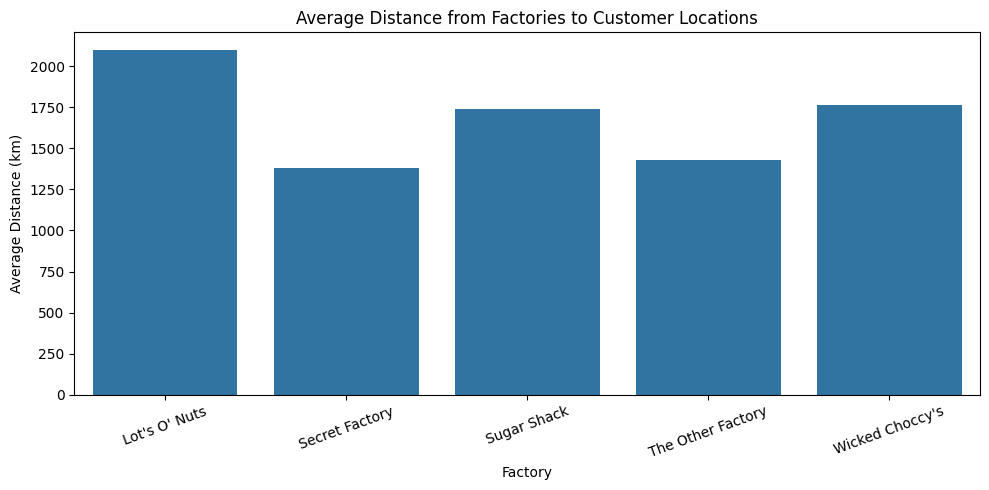

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=factory_distance_summary,
    x="Factory",
    y="Average_Distance"
)

plt.title("Average Distance from Factories to Customer Locations")
plt.xlabel("Factory")
plt.ylabel("Average Distance (km)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

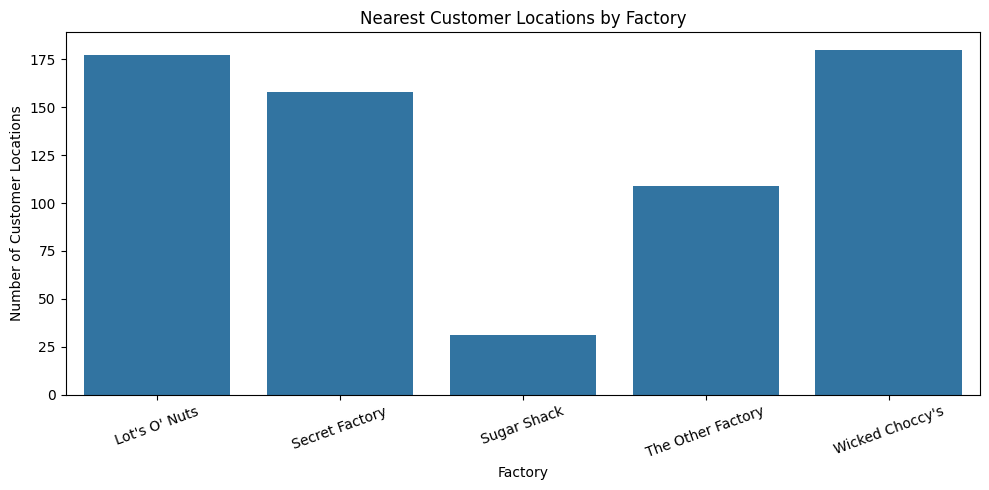

In [35]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=nearest_factory_summary,
    x="Factory",
    y="Nearest Customer Locations"
)

plt.title("Nearest Customer Locations by Factory")
plt.xlabel("Factory")
plt.ylabel("Number of Customer Locations")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [36]:
# Save customer geographical data
customer_geo.to_csv(
    "customer_geographical_data.csv",
    index=False
)

# Save all factory-customer distances
distance_df.to_csv(
    "factory_customer_distances.csv",
    index=False
)

# Save nearest factory assignments
nearest_factory.to_csv(
    "nearest_factory_assignments.csv",
    index=False
)

# Save factory distance summary
factory_distance_summary.to_csv(
    "factory_distance_summary.csv",
    index=False
)

print("All Day 5 datasets saved successfully!")

All Day 5 datasets saved successfully!
